<a href="https://colab.research.google.com/github/Fauzi455/PCVK26_12_M-Fauzi-R/blob/main/Week7_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
NAMA = 'Mohamat Fauzi Rohman'
NIM = '(244107020067)'
print(NAMA, NIM)

Mohamat Fauzi Rohman (244107020067)


# D. TUGAS PRAKTIKUM

## D1. Tugas Individu

1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab
terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah
digunakan pada praktikum minggu lalu, rename file menjadi “Week7.ipynb”. Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-7 berikut.

In [17]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200, secara manual sehingga menghasilkan tampilan seperti berikut:

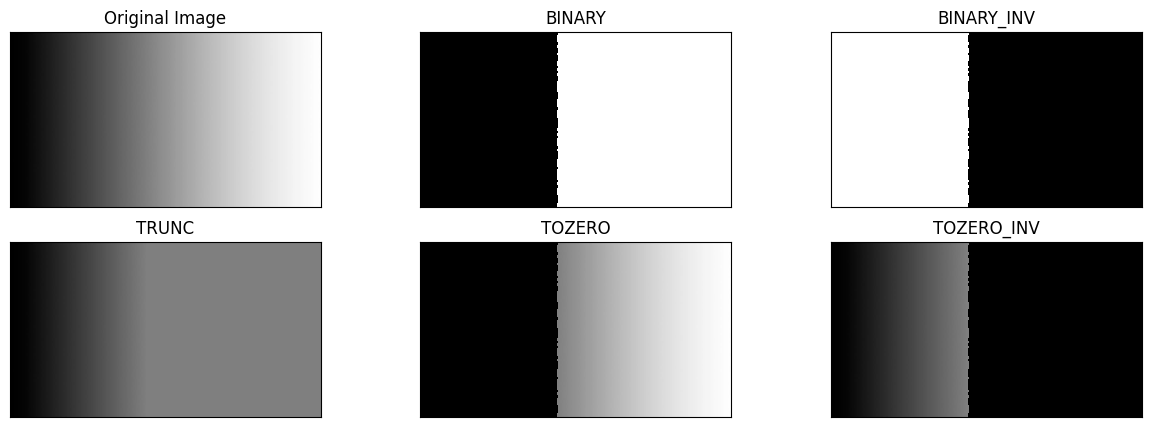

In [19]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020067/gradient.jpg')
img = cv.imread(filename)
thresh = 127 #nilai Threshold yang ditentukan
maxval=255

#1. threshold binary jika pixel di img>127, maka thresh1 bernilai 1(putih) selain itu bernilai 0(hitam)
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)
titles = ['Original Image','BINARY','BINARY_INV','TRUNC','TOZERO','TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

4. Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa
menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap
pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata.
Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 ×
11, C=2, dan sigma=2 untuk Gaussian sehingga menghasilkan tampilan seperti
berikut:

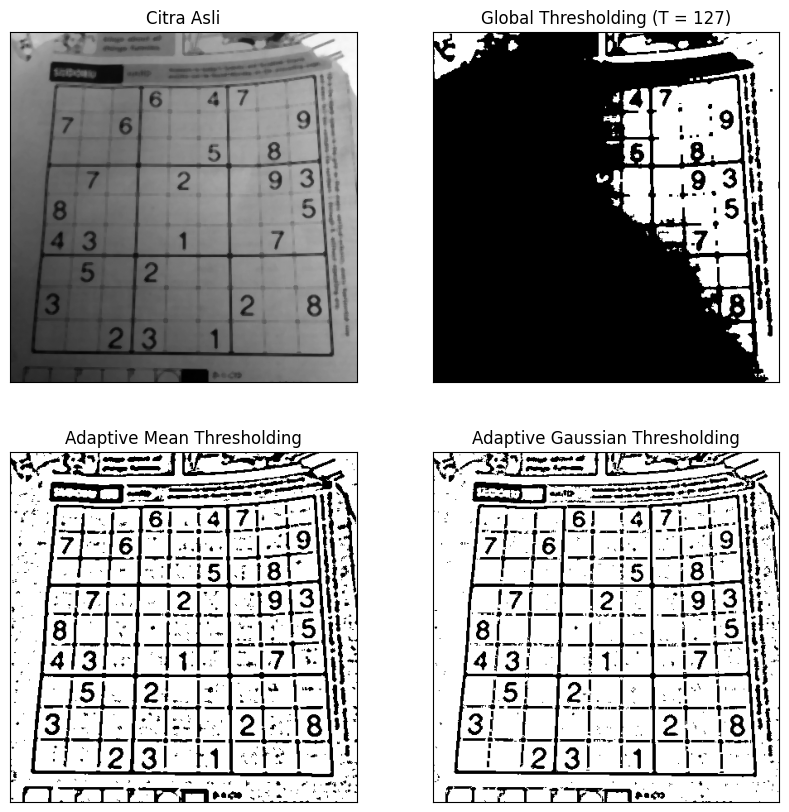

In [20]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020067/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filename),5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

ret,th1 = cv.threshold(gray,thresh,255,cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_MEAN_C,
cv.THRESH_BINARY,11,2)
th3 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_GAUSSIAN_C,
cv.THRESH_BINARY,11,2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']

citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (10,10))
for i in range(len(citra2)):
  plt.subplot(2,2,i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

5. A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold
saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. (gunakan image
lena_gs_lc2.jpg untuk dibandingkan dengan hasil dengan penggunaan library.
B. Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu’s
dengan global threshold biasa)

/tmp/ipykernel_1168/1878740935.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_1168/1878740935.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


96


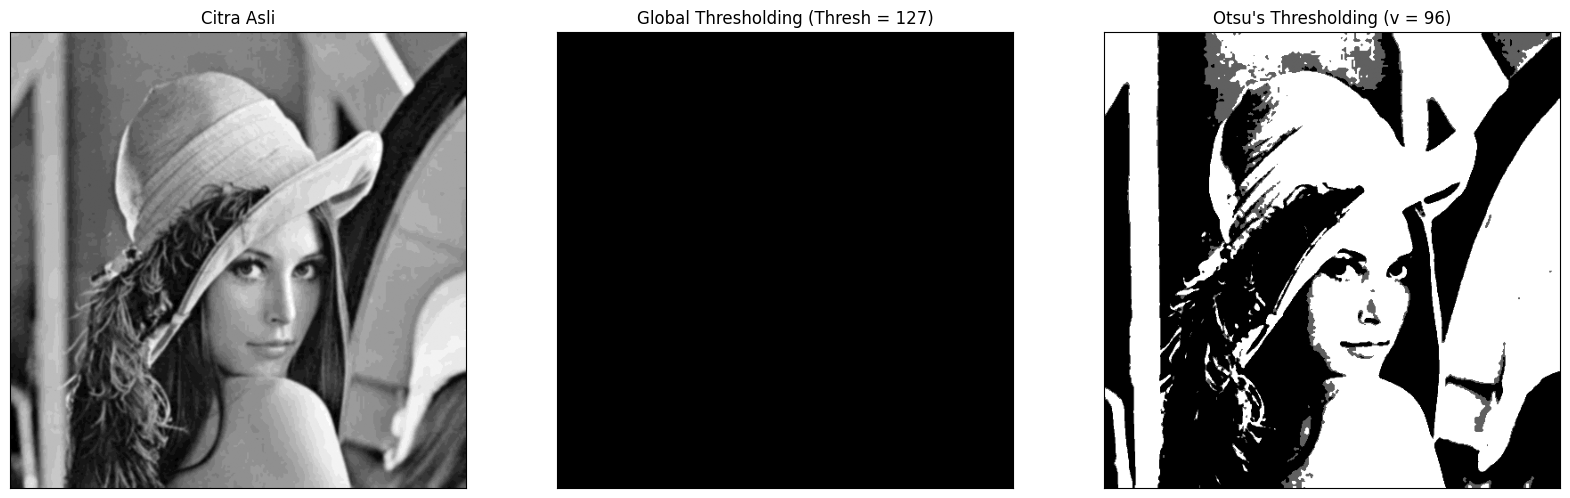

In [33]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020067/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value
  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

**Pertanyaan**: Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?

Jawab :  Karena hasil tampilan Binary Thresholding bernilai 0 (hitam total) karena seluruh nilai intensitas piksel pada citra "Lena Low Contrast" berada di bawah angka ambang batas (Threshold) 127

Pada grafik histogram citra asli, terlihat bahwa seluruh piksel hanya berdistribusi pada area gelap dengan rentang nilai intensitas yang sempit, yaitu di sekitar angka 75 hingga 110. Garis merah yang mempresentasikan nilai ambang batas (Threshold = 127) berada di luar dan di sebelah kanan penyebaran piksel tersebut.

/tmp/ipykernel_1168/2873150309.py:20: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


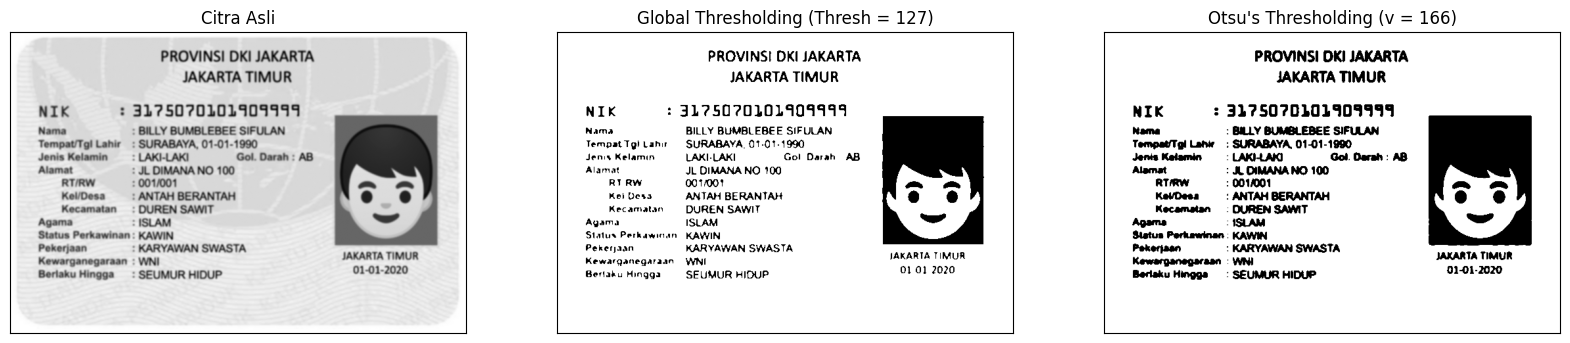

In [34]:
#KTP Fulan
filename = ('/content/drive/MyDrive/PCVK/Images/244107020067/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value
  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

6.  A. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.  

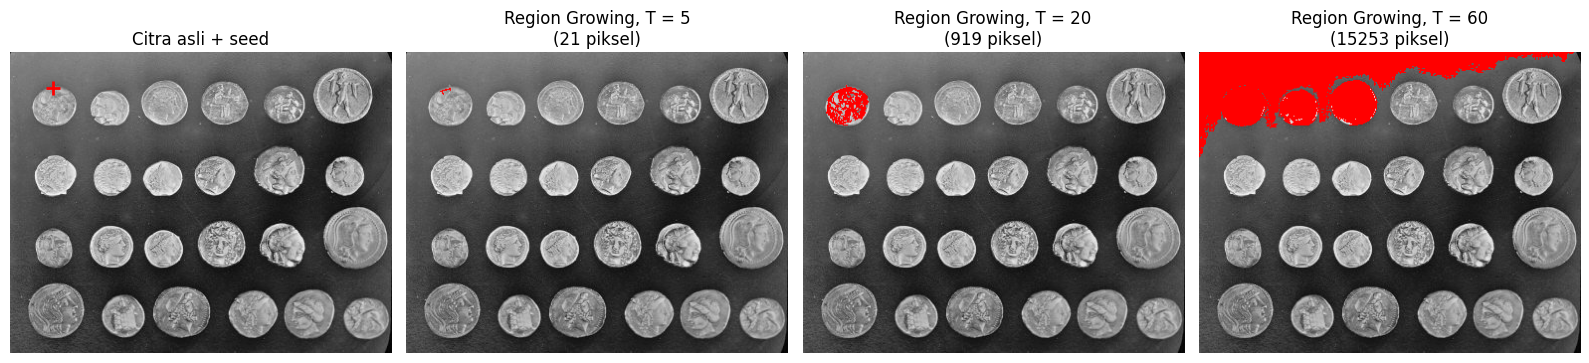

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

img = data.coins()

seed = (36, 43)
tolerances = [5, 20, 60]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

#menampilkan Citra Asli + Seed
axes[0].imshow(img, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=10, markeredgewidth=2) # Tanda plus merah
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

for i, t in enumerate(tolerances):
    mask = flood(img, seed_point=seed, tolerance=t, connectivity=1)

    #memberi warna merah pada area yang tersegmentasi
    img_rgb = np.stack((img,) * 3, axis=-1)
    img_rgb[mask] = [255, 0, 0]

    #menampilkan ke subplot
    axes[i+1].imshow(img_rgb)
    axes[i+1].set_title(f'Region Growing, T = {t}\n({np.sum(mask)} piksel)')
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

  B. Gunakan skimage.segmentation.flood(). Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.  

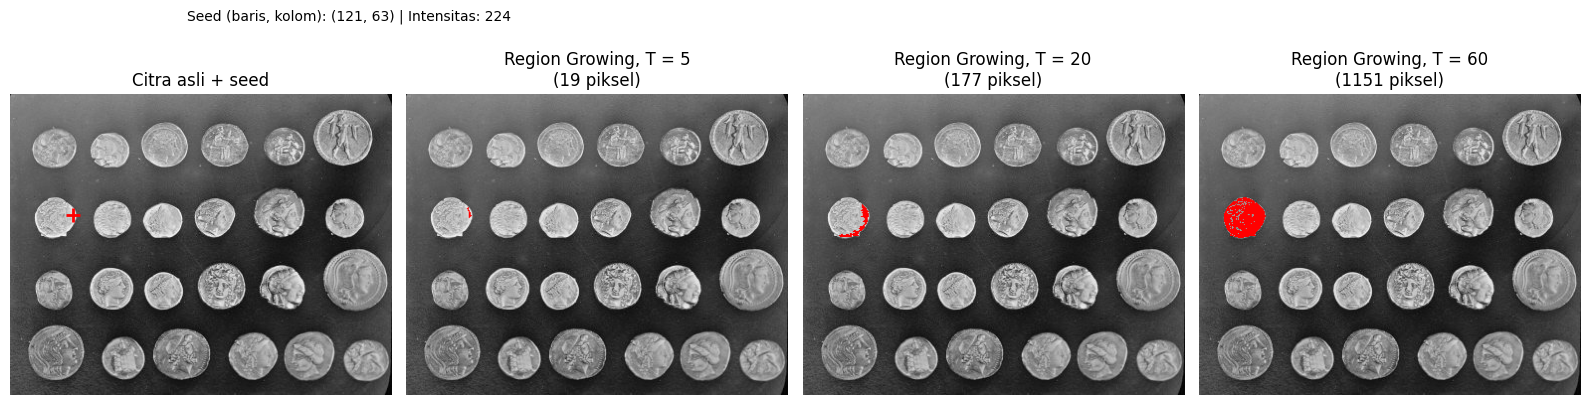

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

seed = (121, 63)
tolerances = [5, 20, 60]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

#menampilkan Citra Asli + Seed
axes[0].imshow(gray, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=10, markeredgewidth=2)
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

for i, t in enumerate(tolerances):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=t,
        connectivity=1  # 4 tetangga untuk citra 2D
    )

    #memberi warna merah pada area yang tersegmentasi
    img_rgb = np.stack((gray,) * 3, axis=-1)
    img_rgb[region] = [255, 0, 0]

    axes[i+1].imshow(img_rgb)
    axes[i+1].set_title(f'Region Growing, T = {t}\n({np.sum(region)} piksel)')
    axes[i+1].axis('off')

plt.suptitle(f'Seed (baris, kolom): {seed} | Intensitas: {gray[seed]}', x=0.12, y=1.05, ha='left', fontsize=10)
plt.tight_layout()
plt.show()

7. Lakukan segmentasi warna pada image ktp_fulan.jpg , munculkan hanya warna yang biru saja. (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna tertentu saja). Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV): kelompok_biru = np.where(    (H >= 85) & (H <= 130) &    (S >= 25) & (V >= 40) )

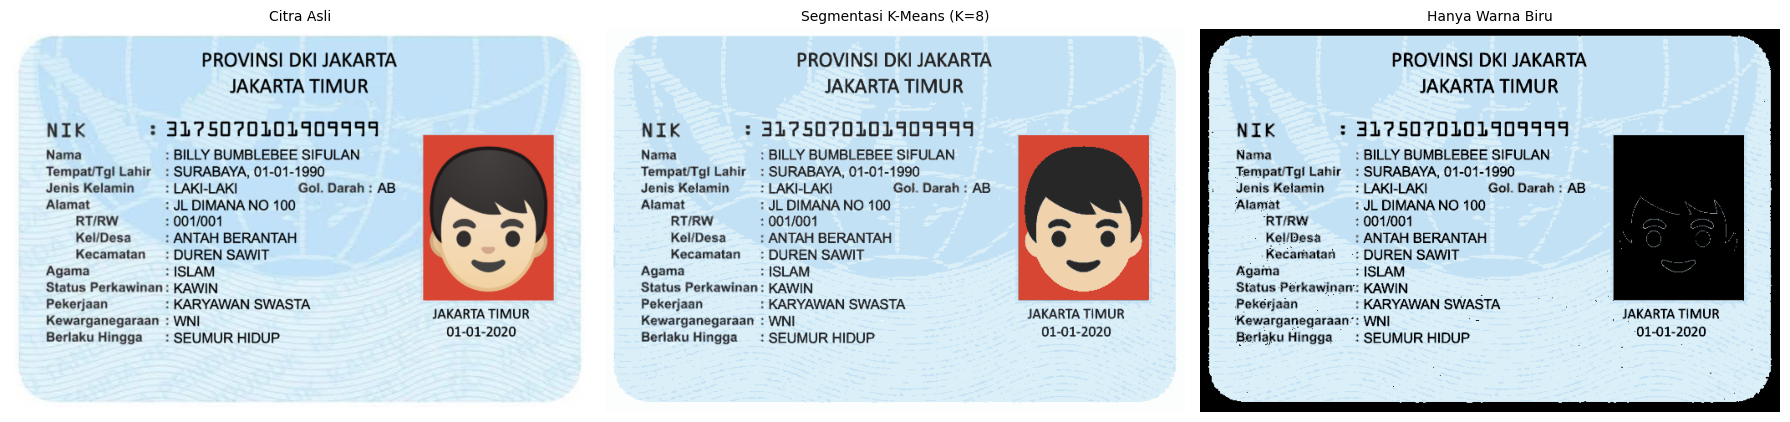

In [52]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

filename = ('/content/drive/MyDrive/PCVK/Images/244107020067/ktp_fulan.jpg')
img = cv2.imread(filename)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

pixel_values = img_rgb.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

#menentukan kriteria K-Means
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 8
_, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

centers = np.uint8(centers)
segmented_data = centers[labels.flatten()]
img_kmeans = segmented_data.reshape(img_rgb.shape)

img_hsv = cv2.cvtColor(img_kmeans, cv2.COLOR_RGB2HSV)
H = img_hsv[:,:,0]
S = img_hsv[:,:,1]
V = img_hsv[:,:,2]

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

#membuat citra kanvas kosong (hitam) dengan ukuran yang sama
img_blue_only = np.zeros_like(img_kmeans)

#mengisi kanvas kosong tersebut hanya pada area 'kelompok_biru'
img_blue_only[kelompok_biru] = img_kmeans[kelompok_biru]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(img_rgb)
axes[0].set_title('Citra Asli', fontsize=10)
axes[0].axis('off')

axes[1].imshow(img_kmeans)
axes[1].set_title('Segmentasi K-Means (K=8)', fontsize=10)
axes[1].axis('off')

axes[2].imshow(img_blue_only)
axes[2].set_title('Hanya Warna Biru', fontsize=10)
axes[2].axis('off')

plt.tight_layout()
plt.show()

## **D2. Tugas Kelompok**

Proses konversi gambar KTP menjadi teks yang dapat mengenali tulisan. Proses konversi gambar menjadi teks dikenal dengan istilah OCR (Optical Character Recognition) adalah teknologi untuk mengenali tulisan pada gambar dan mengubahnya menjadi teks digital yang dapat disalin, diedit, atau diolah.

Siapkan tiga citra untuk dibandingkan:
  
  o Citra berwarna asli.
  
  o Citra hasil segmentasi menggunakan Otsu Thresholding.
  
  o Citra hasil segmentasi menggunakan Adaptive Thresholding.

In [56]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


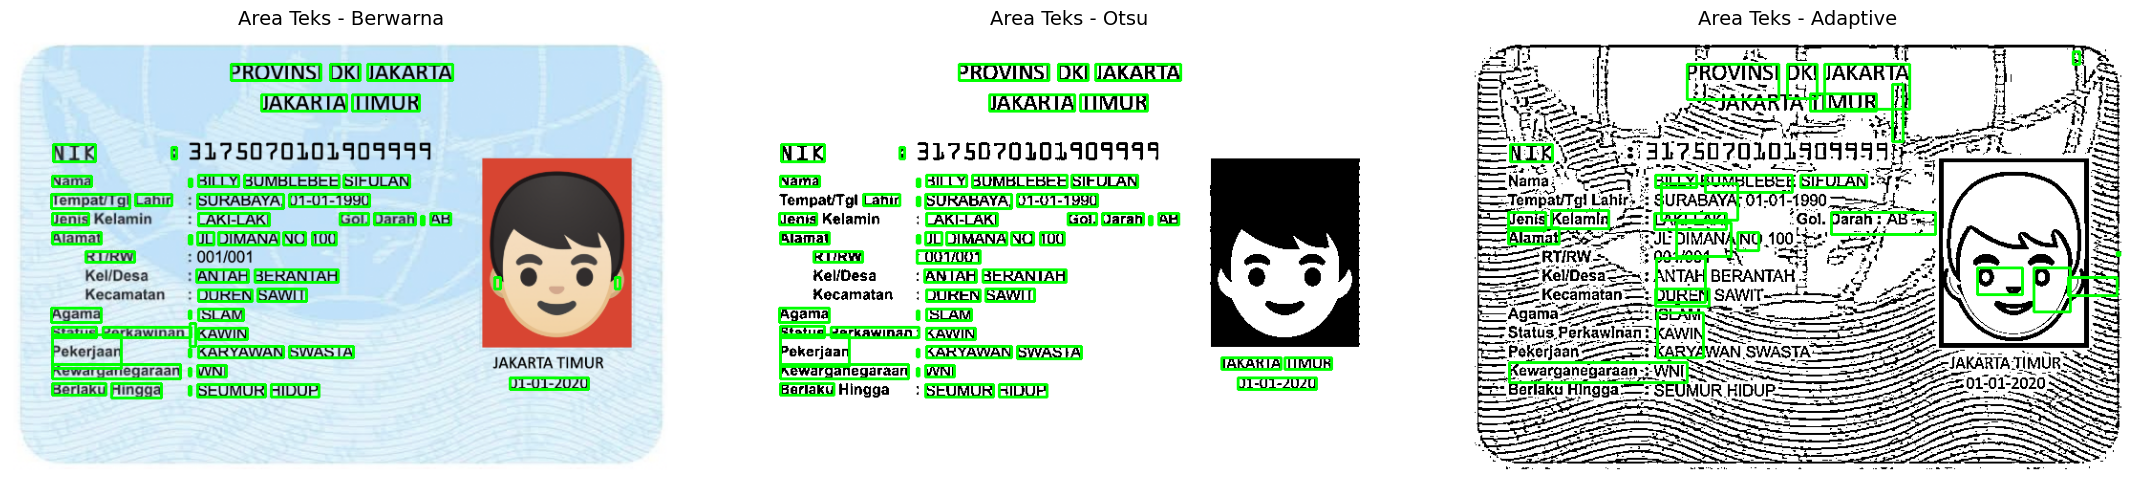


--- Hasil OCR Citra Berwarna ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?50?01019091414
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N /

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SEatIa NUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


--- Hasil OCR Citra Otsu ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?5D?0101401111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW :001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020


--- Hasil OCR Citra Adaptive ---
sr (7 bg pr Ka it 3
“5 | PROVINSI DKI JAKARTA Eh 1
ea SSJAKARTA TIMUR

In [68]:
import difflib
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt

filename = ('/content/drive/MyDrive/PCVK/Images/244107020067/ktp_fulan.jpg')
img = cv.imread(filename)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. Citra berwarna asli
# 2. Citra segmentasi Otsu Thresholding
_, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

custom_config = r'-l ind --psm 6'

teks_warna = pytesseract.image_to_string(img, config=custom_config)
teks_otsu = pytesseract.image_to_string(img_otsu, config=custom_config)
teks_adaptive = pytesseract.image_to_string(img_adaptive, config=custom_config)

fig = plt.figure(figsize=(22, 14))

ax1 = plt.subplot2grid((3, 3), (0, 0))
ax1.imshow(cv.cvtColor(img_box_warna, cv.COLOR_BGR2RGB))
ax1.set_title('Area Teks - Berwarna', fontsize=14, pad=10)
ax1.axis('off')

ax2 = plt.subplot2grid((3, 3), (0, 1))
ax2.imshow(cv.cvtColor(img_box_otsu, cv.COLOR_BGR2RGB))
ax2.set_title('Area Teks - Otsu', fontsize=14, pad=10)
ax2.axis('off')

ax3 = plt.subplot2grid((3, 3), (0, 2))
ax3.imshow(cv.cvtColor(img_box_adaptive, cv.COLOR_BGR2RGB))
ax3.set_title('Area Teks - Adaptive', fontsize=14, pad=10)
ax3.axis('off')

kolom = df_hasil.columns
baris = df_hasil.values
tabel_visual = ax_table.table(cellText=baris, colLabels=kolom, loc='center', cellLoc='center')

tabel_visual.auto_set_font_size(False)
tabel_visual.set_fontsize(12)
tabel_visual.scale(1.2, 2.5)

for (row, col), cell in tabel_visual.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#2c3e50')
    else:
        cell.set_facecolor('#f8f9fa')

plt.tight_layout()
plt.show()

print("")
print("--- Hasil OCR Citra Berwarna ---")
print(teks_warna)
print("\n--- Hasil OCR Citra Otsu ---")
print(teks_otsu)
print("\n--- Hasil OCR Citra Adaptive ---")
print(teks_adaptive)

def draw_text_boxes(image_source, config):
    img_draw = image_source.copy()

    if len(img_draw.shape) == 2:
        img_draw = cv.cvtColor(img_draw, cv.COLOR_GRAY2BGR)

    d = pytesseract.image_to_data(image_source, config=config, output_type=Output.DICT)
    n_boxes = len(d['level'])

    for i in range(n_boxes):
        if int(d['conf'][i]) > 60:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            img_draw = cv.rectangle(img_draw, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return img_draw

#menerapkan fungsi pada ketiga citra
img_box_warna = draw_text_boxes(img, custom_config)
img_box_otsu = draw_text_boxes(img_otsu, custom_config)
img_box_adaptive = draw_text_boxes(img_adaptive, custom_config)


#teks referensi yang benar dari KTP
ground_truth_items = [
    "PROVINSI DKI JAKARTA", "JAKARTA TIMUR", "NIK", "3175070101909999",
    "Nama", "BILLY BUMBLEBEE SIFULAN", "Tempat/Tgl Lahir", "SURABAYA, 01-01-1990",
    "Jenis Kelamin", "LAKI-LAKI", "Gol. Darah", "AB", "Alamat", "JL DIMANA NO 100",
    "RT/RW", "001/001", "Kel/Desa", "ANTAR BERANTAH", "Kecamatan", "DUREN SAWIT",
    "Agama", "ISLAM", "Status Perkawinan", "KAWIN", "Pekerjaan", "KARYAWAN SWASTA",
    "Kewarganegaraan", "WNI", "Berlaku Hingga", "SEUMUR HIDUP"
]

def hitung_akurasi_dan_confidence(ocr_text, image, config, ground_truth):
    ocr_lines = [line.strip() for line in ocr_text.split('\n') if line.strip()]

    item_terbaca_tepat = 0
    total_kecocokan_ratio = 0

    for gt in ground_truth:
        best_ratio = 0
        for line in ocr_lines:
            ratio = difflib.SequenceMatcher(None, gt.lower(), line.lower()).ratio()
            if ratio > best_ratio:
                best_ratio = ratio

        #jika tingkat kemiripannya sangat tinggi (>= 80%), dianggap terbaca tepat
        if best_ratio >= 0.80:
            item_terbaca_tepat += 1

        total_kecocokan_ratio += best_ratio

    #rata-rata persentase kecocokan keseluruhan terhadap target template
    kecocokan_persen = (total_kecocokan_ratio / len(ground_truth)) * 100

    #menghitung "Rata-rata confidence" dari OCR
    d = pytesseract.image_to_data(image, config=config, output_type=Output.DICT)
    confidences = [int(conf) for conf in d['conf'] if int(conf) > 0]

    if len(confidences) > 0:
        rata_confidence = np.mean(confidences)
    else:
        rata_confidence = 0
    return f"{item_terbaca_tepat} / {len(ground_truth)}", f"{kecocokan_persen:.2f}%", f"{rata_confidence:.2f}%"

#menghitung data evaluasi untuk ketiga metode
eval_warna = hitung_akurasi_dan_confidence(teks_warna, img, custom_config, ground_truth_items)
eval_otsu = hitung_akurasi_dan_confidence(teks_otsu, img_otsu, custom_config, ground_truth_items)
eval_adaptive = hitung_akurasi_dan_confidence(teks_adaptive, img_adaptive, custom_config, ground_truth_items)

data_tabel = {
    "Citra masukan OCR": ["Berwarna asli", "Segmentasi Otsu", "Segmentasi Adaptive"],
    "Item terbaca tepat": [eval_warna[0], eval_otsu[0], eval_adaptive[0]],
    "Kecocokan (%)": [eval_warna[1], eval_otsu[1], eval_adaptive[1]],
    "Rata-rata confidence": [eval_warna[2], eval_otsu[2], eval_adaptive[2]]
}

df_hasil = pd.DataFrame(data_tabel)
print("\n--- TABEL EVALUASI OCR ---")
print(df_hasil.to_string(index=False))


## Pertanyaan analisis:

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.

    Jawab : Citra masukan Segmentasi Otsu menghasilkan pembacaan paling tepat, meskipun selisihnya sangat tipis dengan citra berwarna asli. Buktinya, pada tabel terlihat Segmentasi Otsu memiliki tingkat kecocokan tertinggi yaitu 54.59% dengan 4 item terbaca tepat. Citra berwarna asli berada di urutan kedua dengan kecocokan 54.15%

2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.

    Jawab : Banyak teks yang hilang dan kesalahan pengenalan karakter akibat noise (misal: ":" terbaca "1", atau munculnya simbol-simbol acak)

3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.

    Jawab : Tidak selalu. Berdasarkan hasil percobaan Anda, Segmentasi Otsu memang sedikit menaikkan kecocokan dari 54.15% menjadi 54.59%. Namun, Segmentasi Adaptive justru menurunkan ketepatan secara drastis menjadi hanya 41.23% dengan hanya 1 item yang terbaca tepat. Hal ini membuktikan bahwa metode segmentasi yang kurang sesuai dengan karakteristik citra justru dapat merusak bentuk huruf

4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

    Jawab : Pola latar belakang KTP dan variasi warna dapat dikenali sebagai "noise" (gangguan) oleh algoritma OCR. Jika metode segmentasi gagal memisahkan teks dari latar belakang secara bersih, teks akan menyatu dengan latar belakang sehingga tidak bisa diekstrak menjadi karakter

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

    Jawab : Iya, dalam percobaan ini. Berdasarkan tabel, Segmentasi Otsu memiliki Rata-rata confidence tertinggi (81.47%) dan sekaligus memegang Kecocokan tertinggi (54.59%). Citra Berwarna berada di bawahnya dengan confidence 79.96% dan kecocokan 54.15%. Sedangkan Segmentasi Adaptive memiliki confidence terendah (37.37%) yang sejalan dengan persentase kecocokannya yang paling hancur (41.23%)